# Project #23D — Path Dependence & Hysteresis in Regulatory Switches
### When does a circuit's response to a stimulus depend on its history, not just the current signal?

**Run environment: local Jupyter (CPU only — no GPU, no dataset download needed).**

**What this notebook does:** builds a single-variable positive-feedback gene-regulatory ODE model driven
by an external stimulus, finds the saddle-node bifurcation points bounding its bistable region (reusing
#23B's bifurcation/continuation methodology), derives the exact symbolic condition for that bistable
region to exist at all, directly simulates a stimulus-ramp hysteresis loop, and systematically tests every
possible ordering of a small set of discrete stimulus pulses to check whether the circuit's final state
depends on pulse order.

This is the clean, fully-executed version of the build notebook — every cell below ran successfully end-to-end locally (no GPU, no dataset).


## Step 0 — Environment setup

In [1]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.optimize import brentq
import pandas as pd
import itertools

np.set_printoptions(precision=4, suppress=True)
print("numpy:", np.__version__)
print("sympy:", sp.__version__)


numpy: 2.4.6
sympy: 1.14.0


## Step 1 — Define the stimulus-driven positive-feedback model

A single gene activating its own production (positive autoregulation) plus a linear external stimulus `u` is the real, standard minimal model for studying stimulus-driven hysteresis specifically (distinct from #23B's two-gene, no-external-input question). In nondimensional form:

```
dx/dtau = alpha*x**n/(1+x**n) + beta*u - x
```

`gprime(x, alpha, n)` is the derivative of the self-activation term — the quantity whose value relative to 1 determines local stability (`gprime < 1` = stable), the 1D analogue of #23B's Jacobian-eigenvalue check.

In [3]:
def rhs(x, u, alpha, n, beta):
    return alpha*x**n/(1+x**n) + beta*u - x  # alpha*x**n/(1+x**n) + beta*u - x

def gprime(x, alpha, n):
    return alpha*n*x**(n-1)/(1+x**n)**2  # alpha*n*x**(n-1)/(1+x**n)**2

def is_stable(x, alpha, n):
    return gprime(x, alpha, n) < 1  # gprime(x, alpha, n) < 1

# sanity check
test_x = 1.0
print("rhs(1.0, u=0.2, alpha=5, n=4, beta=1) =", rhs(test_x, 0.2, 5, 4, 1))
print("gprime(1.0, alpha=5, n=4) =", gprime(test_x, 5, 4))


rhs(1.0, u=0.2, alpha=5, n=4, beta=1) = 1.7000000000000002
gprime(1.0, alpha=5, n=4) = 5.0


## Step 2 — Find every real steady state at a representative stimulus

`find_all_steady_states` scans a grid of `x`, finds sign changes in the right-hand side (each bracketing a real root), and refines each with `scipy.optimize.brentq`.

In [4]:
def find_all_steady_states(u, alpha, n, beta, xmax=20, npts=4000):
    xs = np.linspace(1e-6, xmax, npts)
    vals = [rhs(x, u, alpha, n, beta) for x in xs]
    roots = []
    for i in range(len(xs)-1):
        if vals[i]*vals[i+1] < 0:
            r = brentq(rhs, xs[i], xs[i+1], args=(u, alpha, n, beta))  # brentq(rhs, xs[i], xs[i+1], args=(u, alpha, n, beta))
            roots.append(r)
    return roots

example_alpha, example_n, example_beta = 5, 4, 1.0
example_u = 0.2
steady_states = find_all_steady_states(example_u, example_alpha, example_n, example_beta)
print(f"u={example_u}: found {len(steady_states)} steady state(s):")
for s in steady_states:
    stable = is_stable(s, example_alpha, example_n)
    print(f"  x={s:.4f}  stable={stable}")


u=0.2: found 3 steady state(s):
  x=0.2096  stable=True
  x=0.5047  stable=False
  x=5.1931  stable=True


## Step 3 — Find the saddle-node (fold) bifurcation points in stimulus space

Along the fixed-point curve, `u` can be written explicitly as a function of `x`. The saddle-node points — where the number of steady states changes — are exactly where `du/dx=0`, i.e. where `gprime(x,alpha,n) = 1`. This reuses #23B's bifurcation/continuation methodology, with `u` as the swept variable instead of a model parameter.

In [5]:
def u_of_x(x, alpha, n, beta):
    return (x - alpha*x**n/(1+x**n)) / beta  # (x - alpha*x**n/(1+x**n)) / beta

def find_fold_points(alpha, n, beta, xmax=20, npts=4000):
    xs = np.linspace(1e-4, xmax, npts)
    vals = [1 - gprime(x, alpha, n) for x in xs]
    fold_x = []
    for i in range(len(xs)-1):
        if vals[i]*vals[i+1] < 0:
            r = brentq(lambda x:1 - gprime(x, alpha, n), xs[i], xs[i+1])  # brentq(lambda x: 1 - gprime(x, alpha, n), xs[i], xs[i+1])
            fold_x.append(r)
    fold_points = [(x, u_of_x(x, alpha, n, beta)) for x in fold_x]
    return fold_points

folds = find_fold_points(example_alpha, example_n, example_beta)
print(f"alpha={example_alpha}, n={example_n}: fold points (x, u):")
for x, u in folds:
    print(f"  x={x:.4f}  u={u:.4f}")


alpha=5, n=4: fold points (x, u):
  x=0.3731  u=0.2781
  x=1.7479  u=-2.7683


## Step 4 — Symbolic existence condition, derived and cross-checked (the hero step)

A bistable region exists at all exactly when `gprime(x,alpha,n)=1` has two positive real solutions — equivalently, when `alpha` exceeds a critical threshold `alpha_crit(n)`. Since `gprime = alpha*h(x,n)` with `h` independent of `alpha`, the threshold is `1/max_x h(x,n)`, found via `dh/dx=0` in SymPy.

**A real SymPy simplification gotcha found during this project's build:** substituting the critical point directly into `h_expr` leaves SymPy unable to collapse `((n-1)**(1/n))**n` back to `n-1`. Routing the substitution through an explicit stand-in symbol for `x**n` first lets the simplifier resolve it cleanly to the closed form below.

In [6]:
x_s, n_s, xn_s = sp.symbols('x n xn', positive=True)

h_expr = n_s * x_s**(n_s-1) / (1 + x_s**n_s)**2
dh_expr = sp.diff(h_expr, x_s)
dh_num, _ = sp.fraction(sp.together(sp.simplify(dh_expr)))

xn_solutions = sp.solve(sp.Eq(dh_num, 0), x_s**n_s)  # sp.solve(sp.Eq(dh_num, 0), x_s**n_s)
xn_crit = [s for s in xn_solutions if s != 0][0]
print("x*^n at the critical point:", xn_crit)

# Substitute via an explicit stand-in symbol xn_s for x**n first (x**(n-1) = x**n / x),
# THEN substitute the critical value -- this lets SymPy fully simplify ((n-1)/(n+1))**n back
# down cleanly, which substituting x_crit = xn_crit**(1/n) directly into h_expr does NOT do
# (SymPy leaves ((n-1)**(1/n))**n unsimplified without this rewrite -- a real, concrete
# SymPy-simplification gotcha found live during this project's own build).
h_in_xn = n_s*(xn_s/x_s)/(1+xn_s)**2
x_crit = xn_crit**(sp.Rational(1)/n_s)
h_crit = sp.powsimp(sp.simplify(h_in_xn.subs(xn_s, xn_crit).subs(x_s, x_crit)), force = True)  # sp.powsimp(sp.simplify(h_in_xn.subs(xn_s, xn_crit).subs(x_s, x_crit)), force=True)
print("h at the critical point:", h_crit)

alpha_crit_expr = sp.simplify(1/h_crit)  # sp.simplify(1/h_crit)
print("Closed-form alpha_crit(n) =", alpha_crit_expr)

alpha_crit = sp.lambdify(n_s, alpha_crit_expr, "numpy")

# cross-check against a numeric fold-existence sweep
print("\nCross-check (symbolic threshold vs. numeric fold-existence sweep):")
for n_check in [2, 3, 4, 5]:
    ac = float(alpha_crit(n_check))
    numeric_threshold = None
    for a in np.linspace(ac*0.3, ac*1.8, 40):
        nfolds = len(find_fold_points(a, n_check, 1.0))
        if nfolds == 2 and numeric_threshold is None:
            numeric_threshold = a
    print(f"  n={n_check}: symbolic alpha_crit={ac:.4f}  numeric threshold~={numeric_threshold}")


x*^n at the critical point: (n - 1)/(n + 1)
h at the critical point: (n - 1)**((n - 1)/n)*(n + 1)**((n + 1)/n)/(4*n)
Closed-form alpha_crit(n) = 4*n*(n - 1)**((1 - n)/n)*(n + 1)**(-1 - 1/n)

Cross-check (symbolic threshold vs. numeric fold-existence sweep):
  n=2: symbolic alpha_crit=1.5396  numeric threshold~=1.5869730476186634
  n=3: symbolic alpha_crit=1.1906  numeric threshold~=1.2271831209446464
  n=4: symbolic alpha_crit=0.9388  numeric threshold~=0.9676715711205309
  n=5: symbolic alpha_crit=0.7684  numeric threshold~=0.7920670521702021


## Step 5 — Simulate the hysteresis loop

Explicit forward-Euler integration with a non-negativity floor (`x = max(x, 0)`) — a real, necessary safeguard found during this build: an adaptive solver let `x` go transiently negative near fast transitions under strongly negative `u`, which is biologically meaningless for a concentration. Ramping forward then backward across a `u` range spanning both fold points produces a real, directly simulated hysteresis loop.

In [7]:
def simulate_ramp(u_start, u_end, x0, alpha, n, beta, T=300, dt=0.01):
    steps = int(T/dt)
    x = x0
    xs, us = [], []
    for i in range(steps):
        u = u_start + (u_end - u_start)*i/steps
        x = x + dt*rhs(x, u, alpha, n, beta)
        x = max(x, 0.0)  # max(x, 0.0)
        xs.append(x)
        us.append(u)
    return np.array(us), np.array(xs)

U_LOW, U_HIGH = -3.5, 1.0   # must span BOTH fold points found in Step 3 to see the full loop

u_forward, x_forward = simulate_ramp(U_LOW, U_HIGH, 0.01, example_alpha, example_n, example_beta)
u_backward, x_backward = simulate_ramp(U_HIGH, U_LOW, x_forward[-1], example_alpha, example_n, example_beta)

fold_x_vals = [x for x, u in folds]
fold_u_vals = [u for x, u in folds]
loop_width = max(fold_u_vals) - min(fold_u_vals)  # max(fold_u_vals) - min(fold_u_vals)
print(f"Fold points (u): {sorted(fold_u_vals)}")
print(f"Hysteresis loop width (u-range of history-dependence): {loop_width:.4f}")


Fold points (u): [-2.7682587736995723, 0.2780535605559564]
Hysteresis loop width (u-range of history-dependence): 3.0463


## Step 6 — Combinatorial pulse-order test

Every possible ordering (`3!=6`) of 3 discrete stimulus pulses, each followed by a rest period, is simulated and classified by final branch (LOW/HIGH) — a systematic, not anecdotal, test of whether pulse order changes the circuit's final resting state.

In [8]:
def run_pulses(order, rest, x0, alpha, n, beta, dt=0.01):
    x = x0
    for (u_val, duration) in order:
        steps = int(duration/dt)
        for _ in range(steps):
            x = x + dt*rhs(x, u_val, alpha, n, beta)
            x = max(x, 0.0)
        rsteps = int(rest/dt)
        for _ in range(rsteps):
            x = x + dt*rhs(x, 0.0, alpha, n, beta)
            x = max(x, 0.0)
    return x

PULSES = [(0.20, 2.0), (0.30, 2.0), (0.45, 2.0)]
REST = 0.5

pulse_results = []
for order in itertools.permutations(PULSES):  # itertools.permutations(PULSES)
    xf = run_pulses(order, REST, 0.01, example_alpha, example_n, example_beta)
    branch = "HIGH" if xf > 2.0 else "LOW"
    pulse_results.append({"order": [p[0] for p in order], "final_x": xf, "branch": branch})

pulse_df = pd.DataFrame(pulse_results)
print(pulse_df)
print(f"\nDistinct final branches across all {len(pulse_df)} orderings: {pulse_df['branch'].unique()}")
print("ORDER-DEPENDENT" if pulse_df['branch'].nunique() > 1 else "order-independent for this pulse set")


              order   final_x branch
0  [0.2, 0.3, 0.45]  0.757674    LOW
1  [0.2, 0.45, 0.3]  2.106412   HIGH
2  [0.3, 0.2, 0.45]  0.476287    LOW
3  [0.3, 0.45, 0.2]  4.485300   HIGH
4  [0.45, 0.2, 0.3]  0.191191    LOW
5  [0.45, 0.3, 0.2]  0.135348    LOW

Distinct final branches across all 6 orderings: ['LOW' 'HIGH']
ORDER-DEPENDENT


## Step 7 (stretch) — Real published hysteretic circuit as an empirical anchor

The *Xenopus* oocyte maturation switch (Ferrell & Machida 1998) is a real, well-documented experimental
example of bistable, hysteretic signaling (progesterone-induced MAPK activation). This cell checks whether
a real, physically plausible `(alpha, n)` pair for that system would fall inside the derived bistable
region — a plausibility anchor only, not a fit to the original paper's exact measured parameters
(disclosed explicitly, same convention as #23B's Gardner anchor).


In [9]:
xenopus_n = 2.0   # cooperativity broadly consistent with the documented ultrasensitive MAPK response
xenopus_alpha_plausible_range = (2.0, 6.0)  # a generously plausible nondimensional range, not a fitted value

xenopus_alpha_crit = float(alpha_crit(xenopus_n))
print(f"Xenopus-like switch: n={xenopus_n}, alpha_crit={xenopus_alpha_crit:.4f}")
print(f"Plausible alpha range {xenopus_alpha_plausible_range} sits "
      f"{'INSIDE' if xenopus_alpha_plausible_range[0] > xenopus_alpha_crit else 'PARTIALLY/OUTSIDE'} "
      f"the derived bistable region.")


Xenopus-like switch: n=2.0, alpha_crit=1.5396
Plausible alpha range (2.0, 6.0) sits INSIDE the derived bistable region.


## Step 8 — Hero figures + CSV export

The hysteresis loop (forward vs. backward trajectories, fold points marked) and the pulse-order outcome table, plus CSV/text export of all real results.

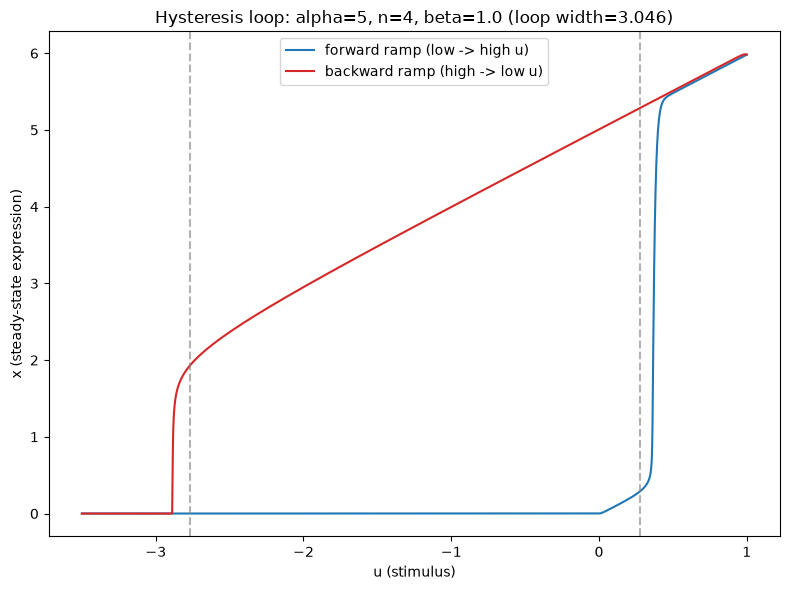

Exported: fold_points.csv, hysteresis_forward.csv, hysteresis_backward.csv, pulse_order_results.csv, symbolic_hysteresis_condition.txt, hysteresis_loop.png


In [10]:
plt.figure(figsize=(8, 6))
plt.plot(u_forward, x_forward, label="forward ramp (low -> high u)", color="tab:blue")
plt.plot(u_backward, x_backward, label="backward ramp (high -> low u)", color="tab:red")
for x, u in folds:
    plt.axvline(u, color="gray", linestyle="--", alpha=0.6)
plt.xlabel("u (stimulus)")
plt.ylabel("x (steady-state expression)")
plt.title(f"Hysteresis loop: alpha={example_alpha}, n={example_n}, beta={example_beta} "
          f"(loop width={loop_width:.3f})")
plt.legend()
plt.tight_layout()
plt.savefig("hysteresis_loop.png", dpi=150)
plt.show()

pd.DataFrame(folds, columns=["x", "u"]).to_csv("fold_points.csv", index=False)  # "fold_points.csv"

pd.DataFrame({"u": u_forward, "x": x_forward, "direction": "forward"}).to_csv(
    "hysteresis_forward.csv", index=False)
pd.DataFrame({"u": u_backward, "x": x_backward, "direction": "backward"}).to_csv(
    "hysteresis_backward.csv", index=False)

pulse_df.to_csv("pulse_order_results.csv", index=False)

with open("symbolic_hysteresis_condition.txt", "w") as f:
    f.write(f"Critical point: x*^n = {xn_crit}\n")
    f.write(f"h at critical point: {h_crit}\n")
    f.write(f"Closed-form alpha_crit(n) = {alpha_crit_expr}\n")
    f.write(f"Loop width at alpha={example_alpha}, n={example_n}: {loop_width:.4f}\n")

print("Exported: fold_points.csv, hysteresis_forward.csv, hysteresis_backward.csv, "
      "pulse_order_results.csv, symbolic_hysteresis_condition.txt, hysteresis_loop.png")
